# Лабораторная работа №4

## Акустическая модель FastSpeech2

Цель работы – обучить акустическую модель на фонемной разметке RUSLAN, проследить обучение и сравнить синтез на разных этапах

В работе было три основных запуска: baseline, модель с pitch и внешними durations, затем тот же вариант с исправленным sample rate


## Коротко

Исправленный запуск выглядит наиболее стабильным: loss снизился с 26,62 до 0,45, а ошибка длительности – с 5,78 до 1,94

До исправления часть аудио сохранялась с частотой 44,1 кГц вместо ожидаемых 22,05 кГц, поэтому сравнивать такие файлы напрямую было некорректно

Полная оценка еще не завершена: в `eval/mcd.csv` сейчас есть 1 пример из 120


## 1. Подготовка

Ноутбук можно запускать из корня репозитория или из директории `labs/lab4_acoustic`

Нужны `numpy`, `matplotlib`, `scipy` и `IPython`


In [1]:
from pathlib import Path
import csv
import re

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Audio, Markdown, display
from scipy.io import wavfile


def find_repo_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "labs" / "lab4_acoustic").is_dir():
            return candidate
    raise FileNotFoundError("Не найден корень репозитория tts_labs_itmo")


REPO_ROOT = find_repo_root()
LAB_DIR = REPO_ROOT / "labs" / "lab4_acoustic"
INFERENCE_DIR = REPO_ROOT / "inference"

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
    "font.size": 11,
})

print(REPO_ROOT)


/home/ivan/workspace/tts_labs_itmo


## 2. Как развивалось решение

Первый проход был baseline без внешних durations и pitch

Во втором проходе добавлены pitch, energy и durations из MFA, а также исправлена работа с манифестом длительностей и лимитом открытых файлов

Третий проход появился после обнаружения ошибки sample rate: в обучение и инференс добавлен `resample=True`, после чего генерация стала соответствовать 22,05 кГц


In [2]:
experiments = {
    "Baseline": LAB_DIR / "runs/baseline/baseline-October-28-2026_11+31AM-b1ba7ed",
    "Pitch + durations": LAB_DIR / "runs/yes_pitch_yes_duration/yes_pitch_yes_duration-October-30-2026_03+11PM-71553a3",
    "Pitch + durations + resample": LAB_DIR / "runs/yes_pitch_yes_duration_fixed_samplerate/yes_pitch_yes_duration_fixed_samplerate-November-03-2026_02+32PM-cae4cca",
}


Во всех запусках использовались batch size 4, learning rate 0,001, Adam, 80 mel-каналов и sample rate 22 050 Гц

- `Baseline` – без pitch, внешних durations и ресемплинга
- `Pitch + durations` – с pitch и внешними durations, но без ресемплинга
- `Pitch + durations + resample` – итоговый вариант с исправленным ресемплингом


## 3. Обучение

Графики строятся по `trainer_0_log.txt`, поэтому для просмотра не нужен TensorBoard

Точки сглаживаются скользящим средним, исходные значения при этом не изменяются


In [3]:
ANSI_RE = re.compile(r"\x1b\[[0-9;]*[A-Za-z]")
STEP_RE = re.compile(r"TIME: ([0-9-]+ [0-9:]+).*GLOBAL_STEP: ([0-9]+)")
METRIC_RE = re.compile(r"\| > ([a-zA-Z0-9_]+): ([+-]?[0-9.eE+-]+)")


def read_training_log(path):
    rows = []
    current = None
    with path.open(errors="ignore") as file:
        for raw_line in file:
            line = ANSI_RE.sub("", raw_line)
            step_match = STEP_RE.search(line)
            if step_match:
                current = {"time": step_match.group(1), "step": int(step_match.group(2))}
                rows.append(current)
                continue
            metric_match = METRIC_RE.search(line)
            if metric_match and current is not None:
                current[metric_match.group(1)] = float(metric_match.group(2))
    return rows


training = {
    name: read_training_log(path / "trainer_0_log.txt")
    for name, path in experiments.items()
}


def smooth(values, window=101):
    values = np.asarray(values, dtype=float)
    if len(values) < window:
        return values
    kernel = np.ones(window) / window
    smoothed = np.convolve(values, kernel, mode="valid")
    return np.concatenate([np.full(window - 1, np.nan), smoothed])


for name, rows in training.items():
    print(f"{name}: {len(rows):,} точек, последний шаг {rows[-1]['step']:,}")


Baseline: 6,166 точек, последний шаг 308,250
Pitch + durations: 12,521 точек, последний шаг 615,200
Pitch + durations + resample: 9,892 точек, последний шаг 494,550


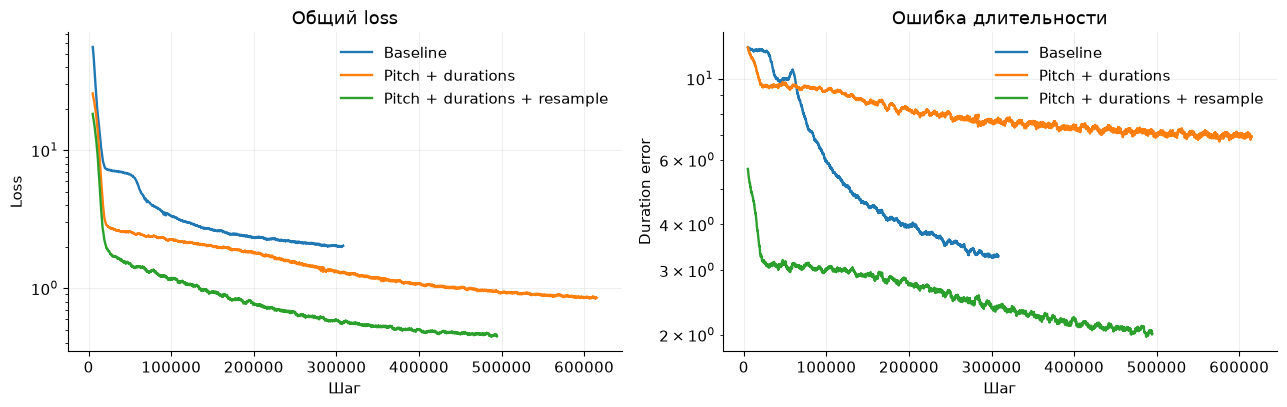

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

for name, rows in training.items():
    steps = [row["step"] for row in rows if "loss" in row]
    losses = [row["loss"] for row in rows if "loss" in row]
    axes[0].plot(steps, smooth(losses), label=name, linewidth=1.7)

    duration_rows = [row for row in rows if "duration_error" in row]
    axes[1].plot(
        [row["step"] for row in duration_rows],
        smooth([row["duration_error"] for row in duration_rows]),
        label=name,
        linewidth=1.7,
    )

axes[0].set(title="Общий loss", xlabel="Шаг", ylabel="Loss", yscale="log")
axes[1].set(title="Ошибка длительности", xlabel="Шаг", ylabel="Duration error", yscale="log")
for axis in axes:
    axis.legend(frameon=False)

plt.tight_layout()
plt.show()


- `Baseline` – 308 250 шагов, loss снизился с 61,32 до 2,53, ошибка длительности с 11,50 до 3,78
- `Pitch + durations` – 615 200 шагов, loss снизился с 40,28 до 0,90, ошибка длительности к концу выросла до 7,65
- `Pitch + durations + resample` – 494 550 шагов, loss снизился с 26,62 до 0,45, ошибка длительности с 5,78 до 1,94


Baseline уверенно сошелся, но итоговый общий loss остался выше из-за отдельного aligner loss

Запуск с pitch и durations без ресемплинга учился дольше всех, но ошибка длительности к концу стала нестабильной

Исправленный запуск дал наиболее ровную динамику и лучший итог среди трех экспериментов


## 4. Как менялся звук

Плееры ниже позволяют быстро пройти путь от раннего baseline до исправленной модели



In [5]:
audio_groups = {
    "Baseline": [
        INFERENCE_DIR / "no_pitch_no_duration/test_70000.wav",
        INFERENCE_DIR / "no_pitch_no_duration/test_250083.wav",
        INFERENCE_DIR / "no_pitch_no_duration/test_308291.wav",
    ],
    "Pitch + durations, sample rate еще не исправлен": [
        INFERENCE_DIR / "yes_pitch_yes_duration/test_270000.wav",
        INFERENCE_DIR / "yes_pitch_yes_duration/test_610000.wav",
        INFERENCE_DIR / "yes_pitch_yes_duration/best_model.wav",
    ],
    "Pitch + durations + resample": [
        INFERENCE_DIR / "yes_pitch_yes_duration_fixed_samplerate/test_370000.wav",
        INFERENCE_DIR / "yes_pitch_yes_duration_fixed_samplerate/test_470000.wav",
        INFERENCE_DIR / "yes_pitch_yes_duration_fixed_samplerate/test_494591.wav",
    ],
}


def show_audio_group(title, paths):
    display(Markdown(f"### {title}"))
    for path in paths:
        if not path.is_file():
            display(Markdown(f"`{path.relative_to(REPO_ROOT)}` – файл не найден"))
            continue
        sample_rate, samples = wavfile.read(path)
        duration = len(samples) / sample_rate
        display(Markdown(f"`{path.name}` – {sample_rate:,} Гц, {duration:.2f} с"))
        display(Audio(filename=str(path)))


for title, paths in audio_groups.items():
    show_audio_group(title, paths)


### Baseline

`test_70000.wav` – 22,050 Гц, 3.42 с

`test_250083.wav` – 22,050 Гц, 3.75 с

`test_308291.wav` – 22,050 Гц, 3.85 с

### Pitch + durations, sample rate еще не исправлен

`test_270000.wav` – 22,050 Гц, 3.58 с

... (2 outputs left out)

### Pitch + durations + resample

`test_370000.wav` – 22,050 Гц, 1.97 с

`test_470000.wav` – 22,050 Гц, 1.81 с

`test_494591.wav` – 22,050 Гц, 2.18 с

### Сравнение с повышенным тоном

Здесь один и тот же этап можно сравнить с постобработкой `+8 полутонов`, а затем с итоговой моделью после исправления sample rate

Повышение тона сделано без изменения длительности и не является отдельным инференсом модели


In [6]:
pitch_comparison = [
    ("Исходный результат до исправления sample rate", INFERENCE_DIR / "yes_pitch_yes_duration/test_610000.wav"),
    ("Тот же результат, pitch +8 полутонов", INFERENCE_DIR / "yes_pitch_yes_duration/test_610000_pitch_up_8st.wav"),
    ("Итоговая модель с исправленным sample rate", INFERENCE_DIR / "yes_pitch_yes_duration_fixed_samplerate/test_494591.wav"),
]

for label, path in pitch_comparison:
    sample_rate, samples = wavfile.read(path)
    duration = len(samples) / sample_rate
    display(Markdown(f"#### {label}"))
    display(Markdown(f"`{path.name}` – {sample_rate:,} Гц, {duration:.2f} с"))
    display(Audio(filename=str(path)))


#### Исходный результат до исправления sample rate

`test_610000.wav` – 22,050 Гц, 5.61 с

#### Тот же результат, pitch +8 полутонов

`test_610000_pitch_up_8st.wav` – 22,050 Гц, 5.61 с

#### Итоговая модель с исправленным sample rate

`test_494591.wav` – 22,050 Гц, 2.18 с

## 5. Спектрограммы

Сравним результат старой модели, тот же файл с повышением pitch на 8 полутонов и финальный исправленный вариант

На графиках показана энергия до 8 кГц, то есть в рабочем диапазоне mel-конфигурации


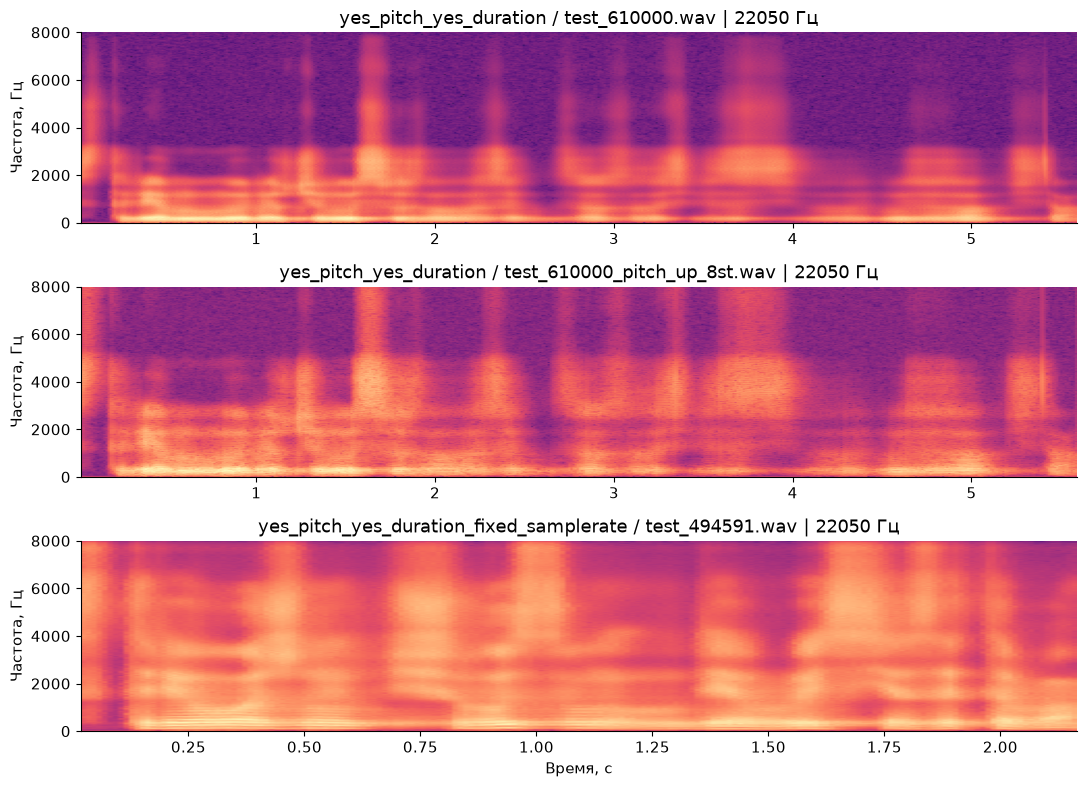

In [7]:
spectrogram_files = [
    INFERENCE_DIR / "yes_pitch_yes_duration/test_610000.wav",
    INFERENCE_DIR / "yes_pitch_yes_duration/test_610000_pitch_up_8st.wav",
    INFERENCE_DIR / "yes_pitch_yes_duration_fixed_samplerate/test_494591.wav",
]


def normalized_audio(path):
    sample_rate, samples = wavfile.read(path)
    if samples.ndim > 1:
        samples = samples.mean(axis=1)
    samples = samples.astype(np.float32)
    peak = np.max(np.abs(samples)) or 1.0
    return sample_rate, samples / peak


fig, axes = plt.subplots(len(spectrogram_files), 1, figsize=(11, 8), sharex=False)
for axis, path in zip(axes, spectrogram_files):
    sample_rate, samples = normalized_audio(path)
    axis.specgram(
        samples,
        NFFT=1024,
        Fs=sample_rate,
        noverlap=768,
        cmap="magma",
        scale="dB",
        mode="magnitude",
    )
    axis.set_ylim(0, 8000)
    axis.set(title=f"{path.parent.name} / {path.name} | {sample_rate} Гц", ylabel="Частота, Гц")
    axis.grid(False)

axes[-1].set_xlabel("Время, с")
plt.tight_layout()
plt.show()


## 6. Оценка на отложенной выборке

Eval выполнен на всех 120 предложениях, которых модель не видела во время обучения

Для каждого предложения доступны natural, copysynth через Griffin-Lim и результат модели


In [8]:
eval_dir = LAB_DIR / "runs/yes_pitch_yes_duration_fixed_samplerate/eval"
with (eval_dir / "mcd.csv").open(encoding="utf-8") as file:
    raw_mcd_rows = list(csv.DictReader(file, delimiter="|"))

mcd_rows = []
for row in raw_mcd_rows:
    mcd_rows.append({
        "id": row["id"],
        "frames_natural": int(row["frames_natural"]),
        "frames_model": int(row["frames_model"]),
        "mcd_model": float(row["mcd_model"]),
        "mcd_constant": float(row["mcd_constant"]),
        "frame_ratio": int(row["frames_model"]) / int(row["frames_natural"]),
    })

model_mcd = np.array([row["mcd_model"] for row in mcd_rows])
constant_mcd = np.array([row["mcd_constant"] for row in mcd_rows])
frame_ratios = np.array([row["frame_ratio"] for row in mcd_rows])
model_wins = int(np.sum(model_mcd < constant_mcd))

print(f"Проверено примеров: {len(mcd_rows)} из 120")
print(f"Средний MCD модели: {model_mcd.mean():.2f} dB")
print(f"Средний MCD constant mel: {constant_mcd.mean():.2f} dB")
print(f"Модель лучше constant mel: {model_wins} из {len(mcd_rows)} примеров")
print(f"Среднее отношение кадров model / natural: {frame_ratios.mean():.3f}")


Проверено примеров: 120 из 120
Средний MCD модели: 37.56 dB
Средний MCD constant mel: 62.56 dB
Модель лучше constant mel: 120 из 120 примеров
Среднее отношение кадров model / natural: 0.778


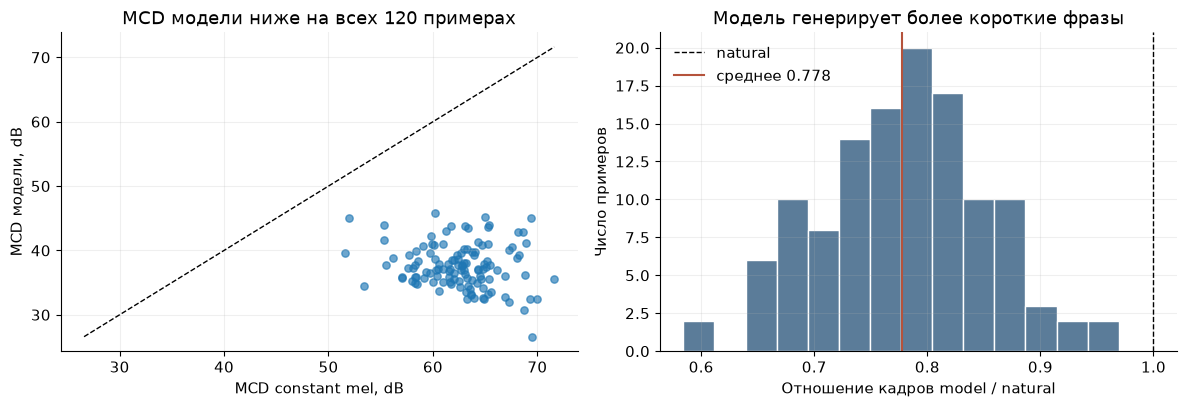

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].scatter(constant_mcd, model_mcd, alpha=0.65, s=28)
lower = min(model_mcd.min(), constant_mcd.min())
upper = max(model_mcd.max(), constant_mcd.max())
axes[0].plot([lower, upper], [lower, upper], color="black", linestyle="--", linewidth=1)
axes[0].set(
    title="MCD модели ниже на всех 120 примерах",
    xlabel="MCD constant mel, dB",
    ylabel="MCD модели, dB",
)

axes[1].hist(frame_ratios, bins=14, color="#5b7c99", edgecolor="white")
axes[1].axvline(1.0, color="black", linestyle="--", linewidth=1, label="natural")
axes[1].axvline(frame_ratios.mean(), color="#b5533c", linewidth=1.5, label=f"среднее {frame_ratios.mean():.3f}")
axes[1].set(
    title="Модель генерирует более короткие фразы",
    xlabel="Отношение кадров model / natural",
    ylabel="Число примеров",
)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()


### Типичный пример

Ниже пример, MCD которого ближе всего к медиане по всей выборке


In [10]:
median_mcd = float(np.median(model_mcd))
typical = min(mcd_rows, key=lambda row: abs(row["mcd_model"] - median_mcd))

display(Markdown(
    f"`{typical['id']}` – MCD {typical['mcd_model']:.2f} dB, "
    f"отношение кадров {typical['frame_ratio']:.3f}"
))

for label, folder in [("Natural", "natural"), ("Copysynth", "copysynth"), ("Model", "model")]:
    display(Markdown(f"#### {label}"))
    display(Audio(filename=str(eval_dir / folder / f"{typical['id']}.wav")))


`019245_RUSLAN` – MCD 37.18 dB, отношение кадров 0.727

#### Natural

#### Copysynth

#### Model

### Лучший и худший примеры

Здесь лучший и худший результаты определяются только по MCD модели


In [11]:
best = min(mcd_rows, key=lambda row: row["mcd_model"])
worst = max(mcd_rows, key=lambda row: row["mcd_model"])

for title, row in [("Лучший", best), ("Худший", worst)]:
    display(Markdown(
        f"#### {title}: `{row['id']}` – MCD {row['mcd_model']:.2f} dB, "
        f"отношение кадров {row['frame_ratio']:.3f}"
    ))
    display(Markdown("Natural"))
    display(Audio(filename=str(eval_dir / "natural" / f"{row['id']}.wav")))
    display(Markdown("Model"))
    display(Audio(filename=str(eval_dir / "model" / f"{row['id']}.wav")))


#### Лучший: `005720_RUSLAN` – MCD 26.60 dB, отношение кадров 0.969

Natural

Model

#### Худший: `001550_RUSLAN` – MCD 45.81 dB, отношение кадров 0.764

Natural

Model

## 7. Выводы

Добавление pitch и внешних durations упростило модель: исчезли потери внутреннего aligner, а исправление sample rate сделало весь аудиотракт согласованным с 22,05 кГц

Лучший по журналам вариант – `yes_pitch_yes_duration_fixed_samplerate`: он дает самый низкий итоговый loss и наиболее устойчивую ошибку длительности

На полной выборке средний MCD модели равен 37,56 dB против 62,56 dB у constant mel. Модель лучше baseline на всех 120 предложениях

Среднее отношение кадров model / natural равно 0,778, медианное – 0,782. Синтез в среднем остается примерно на 22 % короче настоящей речи, поэтому предсказание длительностей остается главным ограничением

Итоговая модель уверенно превосходит простую константную спектрограмму, но качество длительностей и естественность интонации еще можно улучшать
